In [10]:
%pip install reservoirpy

#Referencia para la instalación:
#Nathan Trouvain, Luca Pedrelli, Thanh Trung Dinh, Xavier Hinaut. ReservoirPy: an Efficient and User-Friendly Library to Design Echo State Networks. 2020. ⟨hal-02595026⟩ https://hal.inria.fr/hal-02595026

In [11]:
import reservoirpy as rpy
from reservoirpy.nodes import Reservoir
#reservoirpy.hyper para automatizar la busqueda de los mejores parametros
rpy.set_seed(42)
#reservoir = Reservoir()

In [12]:
#PArte 1 : datos simulados
#usando lorenz 96 su ec.diferencial


#solucion por runge kuta 4
import numpy as np
import os

# parte 1: datos simulados con lorenz 96, resuelto con runge kutta 4
#esto para definir
def lorenz96(x, F):
    # dx_j/dt = (x_{j+1} - x_{j-2}) * x_{j-1} - x_j + F
    Q = len(x)
    dx = np.zeros(Q)
    for j in range(Q):
        # indices modulo Q -> frontera periodica
        dx[j] = (x[(j+1) % Q] - x[(j-2) % Q]) * x[(j-1) % Q] - x[j] + F
    return dx

def paso_rk4(x, F, dt):
    k1 = lorenz96(x, F)
    k2 = lorenz96(x + 0.5*dt*k1, F)
    k3 = lorenz96(x + 0.5*dt*k2, F)
    k4 = lorenz96(x + dt*k3, F)
    return x + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)

def generar_datos(Q=36, F=8.0, dt=0.01, pasos_guardados=20000, cada=5, transitorio=5000):
  # condicion inicial: todo en F y una perturbacion  en x_0 pARA QUE SEA CAHOTIIC
    x = F*np.ones(Q)
    x[0] += 0.01

    # descartamos el transitorio (los datos del inicio pues que se ven muy afectados por las condiciones iniciales que deberian ser arbitrarias)
    for i in range(transitorio):
        x = paso_rk4(x, F, dt)

    # filas = tiempo, columnas = variables
    U = np.zeros((pasos_guardados, Q))
    fila = 0
    paso = 0
    while fila < pasos_guardados:
        x = paso_rk4(x, F, dt)
        if paso % cada == 0:      # guardamos 1 de cada 'cada' pasosss
            U[fila] = x
            fila += 1
        paso += 1

    return U

U = generar_datos()
print("Forma de los datos (tiempo, variables):", U.shape)
print("Primeras 2 filas:\n", U[:2])
#crear la super carpeta de los datoos
os.makedirs("datos", exist_ok=True)
np.save("datos/lorenz96.npy", U)
print("Guardado en datos/lorenz96.npy")

Forma de los datos (tiempo, variables): (20000, 36)
Primeras 2 filas:
 [[-0.72552264  2.46472299  2.60883472  5.45255529  1.74731621 -2.37615039
   0.64781479  8.70511315  0.28256157 -3.43517844  2.86822872  6.73450659
   2.5924355   4.30623275  4.48957027 -3.56568276  1.46102138  2.08373188
   8.02555054 -0.7573825  -1.05184529  1.23361959 11.73920185  0.9242563
  -3.12329854  1.65634572  5.60604995 -0.86357717 -2.52971346  0.93004597
   5.80407296  9.27354826 -0.74485182 -7.00972019  0.02183535  8.62157974]
 [ 1.40011479  2.68229973  3.53175745  5.35580666  0.6273682  -2.16005962
   0.16795516  8.71226538 -0.84413049 -2.77153233  1.98131926  7.52128444
   3.47426206  4.00056155  3.32244208 -3.46651724  1.98718824  3.35209442
   7.62759824 -1.61691273 -0.22402033  1.1561396  11.58827876 -1.03969725
  -2.52276129  1.14342417  5.84380594 -1.42154413 -1.726385    0.52277466
   6.29064089  8.01817897 -5.48787493 -4.59429499 -2.98773587  8.13087605]]
Guardado en datos/lorenz96.npy


In [13]:
#entrenamiento de la red neuronal
from reservoirpy.nodes import Reservoir, Ridge, Input, NVAR
from reservoirpy.observables import nrmse
import matplotlib.pyplot as plt


#cada fila es un instante de tiempo y las columnas son las variables, (20000,36)
U = np.load("datos/lorenz96.npy")   #ahh, los 36 salen de aquí, es pq el sistema lorenz tiene 36 variables

#Hay q elegir cierta cantidad de datos para entrenar la red
n_train = 15000
U_train = U[:n_train]
#otra para los test
U_test = U[n_train:]

media = U_train.mean(axis=0)
std = U_train.std(axis=0)

U_train_norm = (U_train - media) / std   #es para normalizar, pq como F=8, la función tanh se satura
U_test_norm = (U_test - media) / std    #también para normalizar

X_train = U_train_norm[:-1]
X_train = X_train + 0.015 * np.random.default_rng(42).standard_normal(X_train.shape)  #Hay que revisar, no funcionaba bien la predicción sin esta línea, esta agrega ruido
Y_train = U_train_norm[1:]


#Revisar por qué no funciona sin agregar ruido y determinar que tanto cambian los resultados cambiando hiperparámetros


#Parámetros
reservoir = Reservoir(units=2000,#cantidad de neuronas #lo cambie estaba en 1000

    lr=0.25,  #lo cambie estaba en 1.0                #hay que mirar el dt y ajustarlo, pq si es muy grande la red no aprende, y si es muy pequeño tarda mucho en aprender
    sr=0.6,
    input_scaling=0.02,       #toca variar esto pq los datos meten 36 variables simultáneamente y eso puede saturar todo
    input_connectivity=0.1,
    rc_connectivity=0.05,    # Conectividad interna
    seed=42
)
readout = Ridge(ridge=1e-4)  #esto es para los pesos de salida y sirve para que la red no sobreajuste y pueda hacer la predicción


# --- ENTRENAMIENTO: armar [r ; r^2] y entrenar solo la salida ---
reservoir.initialize(X_train[:1])
reservoir.reset()
R = reservoir.run(X_train)                    # estados del reservoir r(t), forma (tiempo, N)
R_feat = np.concatenate([R, R**2], axis=1)    # <-- LA CLAVE: [r ; r^2] SOLO cuadrados puros, SIN cruces
print("Dimension de caracteristicas:", R_feat.shape)   # debe ser (n, 2*N) = (n, 6000)


warmup = 300
readout.fit(R_feat[warmup:], Y_train[warmup:])   # entrena W_out sobre [r ; r^2]


# --- PREDICCION autonoma ---
reservoir.reset()
step_warmup = 150
step_prediccion = 300


R_wu = reservoir.run(U_test_norm[:step_warmup])   # sincroniza el reservoir con datos reales
r_actual = R_wu[-1]                               # ultimo estado del reservoir


feat = np.concatenate([r_actual, r_actual**2])    # [r ; r^2] para el primer paso
u_actual = readout.run(feat.reshape(1, -1)).ravel()


predicciones_norm = np.zeros((step_prediccion, U.shape[1]))
predicciones_norm[0] = u_actual


for t in range(1, step_prediccion):
    r_actual = reservoir.run(u_actual.reshape(1, -1))[-1]   # avanza el reservoir con la propia prediccion
    feat = np.concatenate([r_actual, r_actual**2])          # [r ; r^2]
    u_actual = readout.run(feat.reshape(1, -1)).ravel()     # nueva prediccion
    predicciones_norm[t] = u_actual

Y_pred = predicciones_norm * std + media  #hay q desnormalizar para comparar con datos reales
Y_real = U_test[step_warmup : step_warmup + step_prediccion]


#La predicción no es válida a partir de cierto punto, ya q el sistema está regido por el Tiempo de Lyapunov
#Para nuestros datos generados, es de aproximadamente 1.67 unidades de tiempo. Por lo que entendemos, la predicción es válida apenas para unos 30 pasos aproximadamente.

Dimension de caracteristicas: (14999, 4000)


Error Normalizado: 39.0299


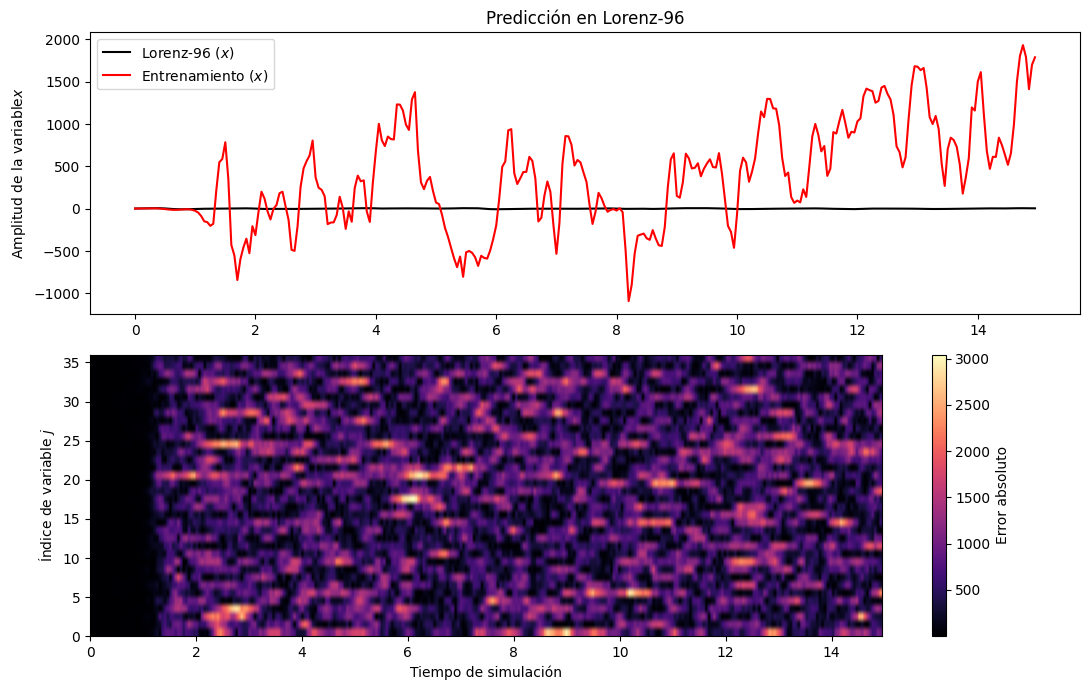

In [14]:
tiempo = np.arange(step_prediccion) * 0.05
fig, axes = plt.subplots(2, 1, figsize=(11, 7))

#Predicción para una variable, puede verse de 0 a 35
axes[0].plot(tiempo, Y_real[:, 11], label="Lorenz-96 ($x$)", color="black")
axes[0].plot(tiempo, Y_pred[:, 11], label="Entrenamiento ($x$)", color="red")
axes[0].set_ylabel("Amplitud de la variable$x$")
axes[0].set_title("Predicción en Lorenz-96")
axes[0].legend()

print(f"Error Normalizado: {nrmse(Y_real[:], Y_pred[:]):.4f}")
#Error para todas las variables en cada paso de tiempo
error_abs = np.abs(Y_real - Y_pred).T
im = axes[1].imshow(error_abs, aspect="auto", origin="lower",
                    extent=[tiempo[0], tiempo[-1], 0, U.shape[1]], cmap="magma")
axes[1].set_ylabel("Índice de variable $j$")
axes[1].set_xlabel("Tiempo de simulación")
fig.colorbar(im, ax=axes[1], label="Error absoluto")

plt.tight_layout()
plt.savefig("prediccion_lorenz96.png")
plt.show()

In [15]:
r"""
    ks_raw.npy    -> snapshots completos (nt, 128, 128), float32
    ks_times.npy  -> tiempo de cada snapshot
    ks_esn.npz    -> u_train, y_train, u_test, y_test (aplanados y normalizados)
"""
from sympy import symbols, exp, pi, Rational
import numpy as np
from shenfun import *

# Parametros que puedes cambiar

N = (128, 128)          # resolucion de la simulacion
dt = 0.01               # paso de tiempo
end_time = 300          # tiempo total simulado
snap_step = 10          # guardar un snapshot cada snap_step pasos (cada 0.1 t)
t_transient = 50        # tiempo inicial que se descarta para la ESN
stride = 4              # reduccion espacial para la ESN: 128 -> 32
train_frac = 0.8        # fraccion de datos para entrenamiento


# Condicion inicial y espacios de funciones

x, y = symbols("x,y", real=True)
ue = exp(-((x - 30*pi)**2 + (y - 30*pi)**2)/100) - Rational(1, 36)/pi

K0 = FunctionSpace(N[0], 'F', dtype='D', domain=(0, 60*np.pi))
K1 = FunctionSpace(N[1], 'F', dtype='d', domain=(0, 60*np.pi))
T = TensorProductSpace(comm, (K0, K1), **{'planner_effort': 'FFTW_MEASURE'})
TV = VectorSpace(T)
Tp = T.get_dealiased()
TVp = VectorSpace(Tp)

u = TrialFunction(T)
v = TestFunction(T)

U = Array(T, buffer=ue)
U_hat = Function(T)
gradu = Array(TVp)
K = np.array(T.local_wavenumbers(True, True, True))
mask = T.get_mask_nyquist()

U_hat = U.forward(U_hat)
U_hat.mask_nyquist(mask)


def LinearRHS(self, u, **params):
    return -div(grad(u)) - div(grad(div(grad(u))))


def NonlinearRHS(self, U, U_hat, dU, gradu, **params):
    gradu = TVp.backward(1j*K*U_hat, gradu)
    dU = Tp.forward(0.5*(gradu[0]*gradu[0] + gradu[1]*gradu[1]), dU)
    dU.mask_nyquist(mask)
    return -dU


def update(self, u, u_hat, t, tstep, wash, snap_step, snapshots, times, **params):
    """Se llama en cada paso de tiempo; aqui se guardan los datos."""
    u_hat.mask_nyquist(mask)
    if wash > 0 and tstep % wash == 0:
        u = u_hat.backward(u)
        u_hat = u.forward(u_hat)

    if tstep % snap_step == 0:
        u = u_hat.backward(u)
        snapshots.append(np.array(u, dtype=np.float32))   # copia 128x128
        times.append(t)
        if len(snapshots) % 100 == 0:
            print(f"t = {t:.2f}, snapshots guardados: {len(snapshots)}", flush=True)


if __name__ == '__main__':
    # 1) Simulacion
    snapshots, times = [], []
    par = {'wash': 1,
           'snap_step': snap_step,
           'snapshots': snapshots,
           'times': times,
           'gradu': gradu}

    integrator = ETDRK4(T, L=LinearRHS, N=NonlinearRHS, update=update, **par)
    integrator.setup(dt)
    U_hat = integrator.solve(U, U_hat, dt, (0, end_time))

    data = np.array(snapshots)            # (nt, 128, 128)
    times = np.array(times)
    np.save('ks_raw.npy', data)
    np.save('ks_times.npy', times)
    print("Datos crudos:", data.shape)

    # 2) Preparacion para la ESN

    # descartar transitorio
    data = data[times >= t_transient]

    # reducir resolucion espacial y aplanar: (nt, 32, 32) -> (nt, 1024)
    data = data[:, ::stride, ::stride]
    nt = data.shape[0]
    X = data.reshape(nt, -1)

    # normalizar con estadisticas del conjunto de entrenamiento
    ntrain = int(train_frac*(nt - 1))
    mu, sigma = X[:ntrain].mean(), X[:ntrain].std()
    X = (X - mu)/sigma

    # prediccion a un paso: entrada u(t), objetivo u(t+1)
    u_in, y_out = X[:-1], X[1:]
    u_train, y_train = u_in[:ntrain], y_out[:ntrain]
    u_test,  y_test = u_in[ntrain:], y_out[ntrain:]

    np.savez('ks_esn.npz',
             u_train=u_train, y_train=y_train,
             u_test=u_test, y_test=y_test,
             mu=mu, sigma=sigma)
    print("Para la ESN -> train:", u_train.shape, " test:", u_test.shape)

    cleanup((T, Tp))

ModuleNotFoundError: No module named 'shenfun'

In [ ]:
"""
    ks_wide.csv       -> una fila por instante de tiempo, una columna por punto
                         de la malla (reducida con STRIDE). Es lo que entra a la ESN.
    ks_vista.png      -> graficas de varios snapshots y de la energia vs tiempo.
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Parametros

STRIDE = 4            # 128 -> 32 puntos por lado (1024 columnas). Usa 8 para menos columnas.
SNAP_INDEX = -1       # snapshot que se exporta en formato largo (-1 = el ultimo)
LBOX = 60*np.pi

# Cargar datos

data = np.load('ks_raw.npy')            # (nt, 128, 128)
times = np.load('ks_times.npy')         # (nt,)
nt, nx, ny = data.shape
print(f"Snapshots: {nt}, malla: {nx}x{ny}, t desde {times[0]:.2f} hasta {times[-1]:.2f}")
print(f"Valores: min={data.min():.3f}, max={data.max():.3f}, "
      f"media={data.mean():.3f}, std={data.std():.3f}")
print("Hay NaN/inf:", not np.isfinite(data).all())

x = np.linspace(0, LBOX, nx, endpoint=False)
y = np.linspace(0, LBOX, ny, endpoint=False)


# 1) CSV ancho: una fila por tiempo, una columna por punto de malla

small = data[:, ::STRIDE, ::STRIDE]
xs, ys = x[::STRIDE], y[::STRIDE]
cols = [f"u_x{xs[i]:.2f}_y{ys[j]:.2f}" for i in range(len(xs)) for j in range(len(ys))]
wide = pd.DataFrame(small.reshape(nt, -1), columns=cols)
wide.insert(0, 'time', times)
wide.to_csv('ks_wide.csv', index=False)
print("Guardado ks_wide.csv con forma", wide.shape)

X, Y = np.meshgrid(x, y, indexing='ij')
# 2) Graficas

idx = np.linspace(0, nt - 1, 4).astype(int)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, i in zip(axes.ravel()[:4], idx):
    im = ax.contourf(X, Y, data[i], 64, cmap='hot')
    ax.set_title(f"t = {times[i]:.1f}")
    ax.set_aspect('equal')
    fig.colorbar(im, ax=ax)

axes[1, 1].plot(times, resumen['energia'])
axes[1, 1].set_title("Energia media vs tiempo")
axes[1, 1].set_xlabel("t")

axes[1, 2].plot(times, small[:, len(xs)//2, len(ys)//2])
axes[1, 2].set_title("Serie temporal en un punto central")
axes[1, 2].set_xlabel("t")

plt.tight_layout()
plt.savefig('ks_vista.png', dpi=120)
plt.show()